# Genetic algorithm on the Fidentis case

The BRKGA of [14](../math/14_genetic-algorithm.md) against the best dispatching rule and CP-SAT, its convergence, and
two Pareto fronts from NSGA-II over the same keys and decoder.

**Two instances** from `data/generator/fidentis.json` (10 orders, one printer, one mill, one oven, default
calendar):

- **fidentis**: two workers. The workers need more days for their work (12.2 calendar days) than the mill (9.5,
  running around the clock), but the mill's attended setups and removals wait for the shift, so both limit the plan.
- **balanced**: a third worker. Mill (9.5) and workers (8.1) need about the same number of days: no clear
  bottleneck.

Each with and without s-batches ([08](../math/08_serial-batches.md)). Objective: makespan. The computing cells store
their results in `notebooks/results/09/` and load them on the next run (recomputed when the parameters change or
with `RECOMPUTE = True`). Rebuild with `uv run python notebooks/build_09_ga.py`.

In [1]:
%matplotlib inline
import hashlib
import json
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt

from simulation.model.schedule import Schedule
from simulation.viz import plot_days

from ga_runs import (CASES, FIDENTIS, FRONT_TIME, SETTINGS, TIME_LIMIT, cpsat_run, front_run, ga_run, instance,
                     loads, rule_run)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "notebooks/results/09"
RECOMPUTE = False  # True: compute everything again (after a change of planners or decoder)
SEEDS = range(1, 7)
DIGEST = hashlib.sha256((FIDENTIS.model_dump_json() + repr((CASES, SETTINGS, TIME_LIMIT, FRONT_TIME, list(SEEDS))))
                        .encode()).hexdigest()[:12]
COLORS = {"best rule": "#2a78d6", "CP-SAT": "#eb6834", "GA": "#1baf7a", "GA no-delay": "#eda100"}  # fixed order
PLANNERS = list(COLORS)
DAY = 1440


def cached(name, compute):
    # compute() as JSON in RESULTS/<name>.json: loaded if stored for the same parameters, else computed
    path = RESULTS / f"{name}.json"
    if not RECOMPUTE and path.exists() and (data := json.loads(path.read_text(encoding="utf-8")))["digest"] == DIGEST:
        print(f"loaded {path.relative_to(ROOT)}")
        return data["value"]
    value = compute()
    RESULTS.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps({"digest": DIGEST, "value": value}) + "\n", encoding="utf-8")
    return value

## 1. The two instances

Days a resource needs for its work alone (machines 24 h a day; workers 510 minutes per working day each, five
working days a week, given in calendar days).

In [2]:
for case in CASES:
    print(f"{case:9}", loads(instance(case, True)))

fidentis  {'oven': 0.5, 'mill': 9.5, 'print': 2.2, 'workers': 12.2}
balanced  {'oven': 0.5, 'mill': 9.5, 'print': 2.2, 'workers': 8.1}


## 2. Comparison at equal wall time

Per instance and variant: the best of the 15 rule plans (5 sequencing x 3 assignment variants), CP-SAT (60 s on all
cores, hinted with the best rule plan), and the GA (60 s on one core, 6 seeds, 6 runs in parallel so each keeps a
core) with the delay window (D^max = 100 minutes, logarithmic, [14](../math/14_genetic-algorithm.md) §3) and
without it (D^max = 0). Every plan passes the checker.

In [3]:
def compare():
    rows = [rule_run(c, sb) for c in CASES for sb in (False, True)]
    rows += [cpsat_run(c, sb) for c in CASES for sb in (False, True)]
    jobs = [(c, sb, s, seed) for c in CASES for sb in (False, True) for s in SETTINGS for seed in SEEDS]
    with ProcessPoolExecutor(max_workers=6) as pool:
        rows += list(pool.map(ga_run, *zip(*jobs, strict=True)))
    return rows


ROWS = cached("comparison", compare)
assert all(r["feasible"] for r in ROWS)
print(f"{'instance':9} {'s-batch':7} {'planner':12} {'best':>6} {'mean':>7} {'worst':>6} {'overtime':>8} "
      f"{'worker':>6} {'batches':>7} {'saved':>5} {'gens':>5}")
for case in CASES:
    for sb in (False, True):
        for planner in PLANNERS:
            rs = [r for r in ROWS if r["case"] == case and r["s_batches"] == sb and r["planner"] == planner]
            best = min(rs, key=lambda r: r["makespan"])
            gens = round(mean(r["generations"] for r in rs)) if "generations" in best else ""
            print(f"{case:9} {'with' if sb else 'without':7} {planner:12} {best['makespan']:6} "
                  f"{mean(r['makespan'] for r in rs):7.0f} {max(r['makespan'] for r in rs):6} {best['overtime']:8} "
                  f"{best['worker_minutes']:6} {best['batches']:7} {best['saved']:5} {gens:>5}")

loaded notebooks\results\09\comparison.json
instance  s-batch planner        best    mean  worst overtime worker batches saved  gens
fidentis  without best rule     25980   25980  25980        0   8870       0     0      
fidentis  without CP-SAT        23060   23060  23060     1125   8870       0     0      
fidentis  without GA            23130   23230  23480      655   8830       0     0    16
fidentis  without GA no-delay   23100   23228  23380      707   8830       0     0    17
fidentis  with    best rule     24850   24850  24850        0   8105      31   725      
fidentis  with    CP-SAT        23110   23110  23110      845   8470      22   360      
fidentis  with    GA            23100   23140  23280      904   8255      32   575    25
fidentis  with    GA no-delay   23100   23155  23400      881   8315      33   515    23
balanced  without best rule     24540   24540  24540        0   8830       0     0      
balanced  without CP-SAT        22170   22170  22170      250   88

Makespan in days per instance (rows) and variant (columns); the GA's six seeds as dots, their mean as a
bar.

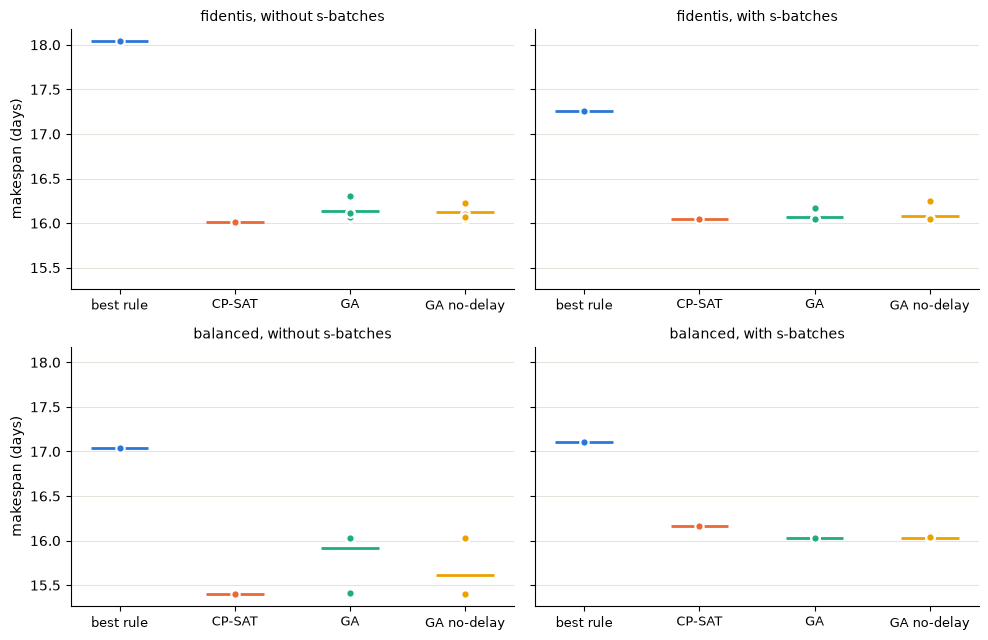

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharey=True)
for i, case in enumerate(CASES):
    for j, sb in enumerate((False, True)):
        ax = axes[i][j]
        for x, planner in enumerate(PLANNERS):
            vals = [r["makespan"] / DAY for r in ROWS
                    if r["case"] == case and r["s_batches"] == sb and r["planner"] == planner]
            ax.scatter([x] * len(vals), vals, s=36, color=COLORS[planner], edgecolor="white", linewidth=1.5,
                       zorder=3)
            ax.hlines(mean(vals), x - 0.25, x + 0.25, color=COLORS[planner], linewidth=2)
        ax.set_xticks(range(len(PLANNERS)), PLANNERS, fontsize=9)
        ax.set_title(f"{case}, {'with' if sb else 'without'} s-batches", fontsize=10)
        ax.grid(axis="y", color="#e4e3dc", linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[i][0].set_ylabel("makespan (days)")
fig.tight_layout()
plt.show()

## 3. Convergence

The GA's best makespan after the seeding (generation 0) and after every generation, with s-batches, one line per
seed. Generations take the same wall time per run only roughly (the decode time depends on the plan).

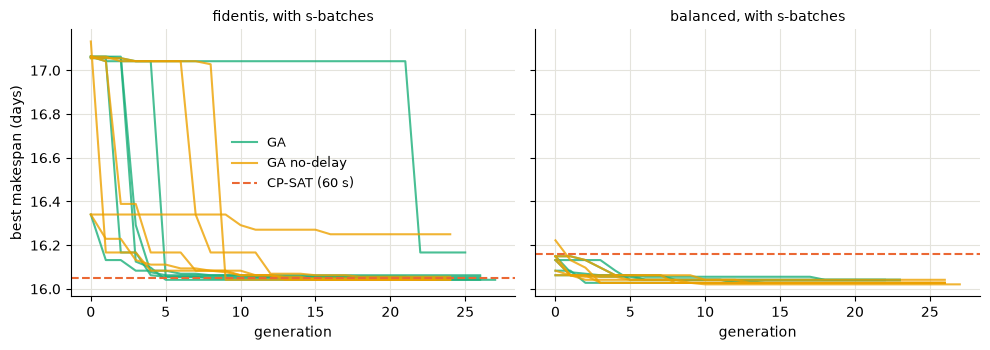

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, case in zip(axes, CASES, strict=True):
    for setting in SETTINGS:
        for k, r in enumerate(r for r in ROWS if r["case"] == case and r["s_batches"] and r["planner"] == setting):
            ax.plot(range(len(r["history"])), [v / DAY for v in r["history"]], color=COLORS[setting], linewidth=1.5,
                    alpha=0.8, label=setting if k == 0 else None)
    cp = next(r for r in ROWS if r["case"] == case and r["s_batches"] and r["planner"] == "CP-SAT")
    ax.axhline(cp["makespan"] / DAY, color=COLORS["CP-SAT"], linewidth=1.5, linestyle="--", label="CP-SAT (60 s)")
    ax.set_title(f"{case}, with s-batches", fontsize=10)
    ax.set_xlabel("generation")
    ax.grid(color="#e4e3dc", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("best makespan (days)")
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 4. Pareto fronts (NSGA-II)

NSGA-II over the same keys and decoder ([14](../math/14_genetic-algorithm.md) §3a), 120 s per front, with
s-batches. Left: makespan against overtime. Right: makespan against the total start deviation from the best rule
plan (stability, Wu et al. 1993): how far the plan must move away from a given plan to end earlier. Every point is
a feasible plan that no other found plan beats in both objectives.

loaded notebooks\results\09\fronts.json


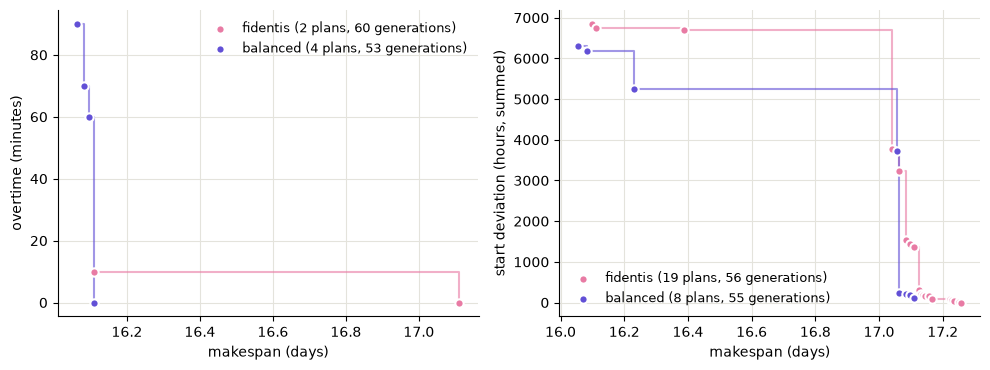

fidentis  overtime  [[23200, 10], [24640, 0]]
fidentis  stability [[23180, 410860], [23200, 404885], [23600, 401753], [24540, 226139], [24570, 194360], [24600, 92375], [24620, 86560], [24640, 82600], [24660, 18590], [24670, 13180], [24680, 11300], [24690, 10370], [24705, 9000], [24720, 5670], [24800, 4640], [24810, 3470], [24820, 2680], [24840, 1160], [24850, 0]]
balanced  overtime  [[23130, 90], [23160, 70], [23180, 60], [23200, 0]]
balanced  stability [[23120, 378673], [23160, 370320], [23370, 315468], [24560, 223130], [24570, 14485], [24600, 13175], [24620, 10705], [24640, 6385]]


In [6]:
def fronts():
    jobs = [(c, k) for c in CASES for k in ("overtime", "stability")]
    with ProcessPoolExecutor(max_workers=4) as pool:
        return list(pool.map(front_run, *zip(*jobs, strict=True)))


FRONTS = cached("fronts", fronts)
assert all(f["feasible"] for f in FRONTS)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, kind, ylabel, scale in ((axes[0], "overtime", "overtime (minutes)", 1),
                                (axes[1], "stability", "start deviation (hours, summed)", 60)):
    for case, color in zip(CASES, ("#e87ba4", "#6250d6"), strict=True):  # instance colors, not planner colors
        f = next(f for f in FRONTS if f["case"] == case and f["kind"] == kind)
        xs, ys = [v[0] / DAY for v in f["front"]], [v[1] / scale for v in f["front"]]
        ax.step(xs, ys, where="post", color=color, linewidth=1.5, alpha=0.6)
        ax.scatter(xs, ys, s=36, color=color, edgecolor="white", linewidth=1.5, zorder=3,
                   label=f"{case} ({len(xs)} plans, {f['generations']} generations)")
    ax.set_xlabel("makespan (days)")
    ax.set_ylabel(ylabel)
    ax.grid(color="#e4e3dc", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()
for f in FRONTS:
    print(f"{f['case']:9} {f['kind']:9} {f['front']}")

## Findings (run of 2026-11-20)

**GA against CP-SAT.** At equal wall time (60 s; GA on one core, CP-SAT on 12 threads) the GA reaches CP-SAT's level
on the fidentis instance (with s-batches 23100 to 23280 against 23110; without 23130 to 23480 against 23060) and is
better on the balanced instance with s-batches on every seed (23070 to 23100 against 23270). On the balanced
instance without s-batches CP-SAT is better (22170; GA mean 22482 to 22918, the seeds split between about 22200 and
23080, one working day apart). The GA now runs 14 to 25 generations, after the decoder became 2 to 4 times faster.

**CP-SAT and its hint.** With the best rule plan as hint (MWKR, 24850) CP-SAT reaches 23110 with s-batches; notebook
08, hinted with SPT/ECT (30730), got 24500. The earlier finding "the GA beats CP-SAT with s-batches"
([14](../math/14_genetic-algorithm.md) §5a) came mostly from the weak hint.

**s-batches and the makespan.** On fidentis they leave the best makespan unchanged (23100 either way) and save 515 to
725 setup minutes. On the balanced instance they make it longer for both CP-SAT (22170 to 23270) and the GA (22180 to
23070), though they save about 600 worker minutes: a batch couples operations of different orders, which then start
together. For the GA every ready partner joins (greedy join, [14](../math/14_genetic-algorithm.md) §6); CP-SAT may
leave a slot empty, so its worse value is a matter of search, not of the model.

**Delay window.** With the logarithmic map (at most 100 minutes) the delay no longer hurts on fidentis (means 23140
against 23155 with s-batches) but brings no gain under makespan either; on balanced without s-batches its mean is
worse (22918 against 22482), with 6 seeds a weak difference.

**Convergence.** The best makespan falls in steps of about a working day; most seeds reach their level within 5 to 10
generations, one seed on fidentis stayed a day behind until generation 21. On the balanced instance with s-batches
the seeding is already within 0.2 days of the end result.

**Fronts.** Makespan against overtime: on fidentis 10 minutes of overtime save a whole working day (24640 to 23200);
on balanced 90 minutes save 70 minutes. Makespan against start deviation from the best rule plan: within one day
step the deviation falls to almost nothing for little makespan (fidentis: 24660 at 18590 summed minutes, 24850 at
0), while the next day step costs a move of most operations (about 400000 summed minutes): stability is cheap within
a day, expensive across one, in line with Wu et al. (1993) for small changes.

Limits: 6 seeds, wall-clock limits, makespan only (the thesis objective is lexicographic with tardiness), static
instances; one NSGA-II run per front (120 s). Own reading of the numbers.

## 5. The best GA plan

The first working days of the best GA plan on the fidentis instance with s-batches, per worker (one bar per batch,
labelled with all its orders).

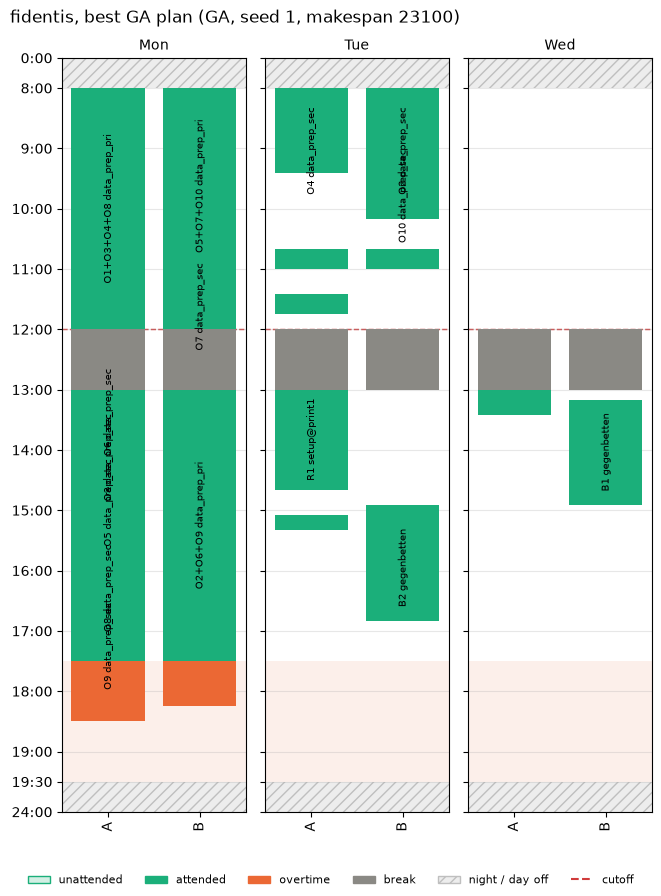

In [7]:
best = min((r for r in ROWS if r["case"] == "fidentis" and r["s_batches"] and "plan" in r),
           key=lambda r: r["makespan"])
plan = Schedule.model_validate(best["plan"])
plot_days(instance("fidentis", True), plan.assignments, plan.breaks, days=3, rows="workers",
          title=f"fidentis, best GA plan ({best['planner']}, seed {best['seed']}, makespan {best['makespan']})")
plt.show()